## TEMA
El debate internacional en torno al calentamiento global presenta enfoques divergentes. Por un lado, las directrices europeas atribuyen el aceleramiento climático de forma directa al incremento de las emisiones de dióxido de carbono derivadas de la actividad antrópica. Por otro lado, posturas impulsadas por diversas grandes potencias argumentan un peso mayor de la variabilidad climática natural y los ciclos planetarios de largo plazo frente al impacto antrópico.

Para aportar evidencia empírica a este debate, el presente estudio aborda la atmósfera bajo un estricto enfoque de contabilidad de masas ("caja de balance"). En este modelo, la atmósfera actúa como un volumen de control donde la acumulación neta de carbono representa el desequilibrio entre las emisiones totales inyectadas y la capacidad real de los sumideros planetarios (océanos y biosfera terrestre) para reabsorberlo. Mediante el cruce analítico de las series históricas de la NOAA (1958-2025), los registros globales de emisiones de la OWID y las anomalías térmicas globales, se evalúa numéricamente esta dinámica.

# HIPOTESIS

Existe una sólida base científica que, apoyada en los modelos del ciclo del carbono, sostiene que el incremento exponencial y continuado del CO₂ atmosférico está dominado por el forzamiento antropogénico (combustibles fósiles y cambios de uso del suelo), cuya tasa de emisión supera con margen la capacidad dinámica de asimilación de los sumideros naturales.

El presente análisis cuantitativo de los datos históricos, tiene como propósito confirmar o desmentir empíricamente si los factores determinantes de la aceleración del calentamiento global son:

- El crecimiento demográfico global: correlacionar la expansión de la población mundial con el incremento absoluto de las emisiones agregadas.

- Las emisiones antropogénicas directas: aislar y medir el peso específico de la quema de combustibles fósiles frente al balance global acumulado de carbono.

- La deforestación y el cambio de uso del suelo: cuantificar el impacto del deterioro de la superficie forestal en la reducción de las reservas de carbono en los ecosistemas.

- La saturación o pérdida de eficiencia de los sumideros naturales: evaluar si la capacidad de absorción de los océanos y los ecosistemas terrestres muestra signos de fatiga o estancamiento ante el volumen creciente de emisiones, alterando el ritmo natural del ciclo del carbono.


# DATASET

La información de registros y datos se han descargado de los siguientes organismos:

NOAA: National Oceanic and Atmospheric Administration (Administración Nacional Oceánica y Atmosférica). Es la agencia científica de los Estados Unidos encargada de monitorizar y estudiar los océanos, el clima y la atmósfera a nivel global. En tu análisis, es la entidad oficial que gestiona el observatorio de Mauna Loa y publica el registro histórico continuo de la concentración de CO2 atmosférico desde 1958.

OWID: Our World in Data. Es una influyente publicación de investigación científica y divulgación basada en la Universidad de Oxford. Analiza y recopila datos empíricos a gran escala sobre el desarrollo mundial (población, salud, energía y medio ambiente). De aquí se obtienen las series históricas de emisiones antropogénicas globales (respaldadas por el Global Carbon Project) para cruzarlas con los datos descargados de la NOAA.


In [2]:
import pandas as pd
from pathlib import Path
from Funciones import descargar_datos_noaa
from Funciones import descargar_owid_co2
from Funciones import descargar_temp_noaa
import matplotlib.pyplot as plt


## PATRÓN DE TRABAJO
- Descarga de información
- Tratamiento de la información y depuración de la misma
- Análisis de la información medianta diagramas/gráficas.
- Conclusiones para confirmar o desmentir las hipótesis planteadas

# 1-NOAA


In [ ]:
print("--- Obtención de datos de balance de CO2 de la NOAA ---")

# Llamar a la función específica de la NOAA
descargar_datos_noaa()

print("--- PROCESO FINALIZADO ---")



--- INICIANDO SCRIPT DE LA NOAA ---
Iniciando la descarga del archivo de la NOAA...
   [ÉXITO] Archivo guardado correctamente en: emisiones_data\noaa_co2_mensual_mlo.csv
--- PROCESO FINALIZADO ---


In [4]:
# Ya tengo el csv guardado y no tengo que volver a descargarlo. 
path = Path("emisiones_data/noaa_co2_mensual_mlo.csv")
df = pd.read_csv(path, comment="#")
df

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99
...,...,...,...,...,...,...,...,...
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            823 non-null    int64  
 1   month           823 non-null    int64  
 2   decimal date    823 non-null    float64
 3   average         823 non-null    float64
 4   deseasonalized  823 non-null    float64
 5   ndays           823 non-null    int64  
 6   sdev            823 non-null    float64
 7   unc             823 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 51.6 KB


In [6]:
df = df.rename(columns={
        "year": "año",
        "month": "mes",
        "decimal date": "fecha_decimal",
        "average": "promedio ppm",
        "deseasonalized": "desestacionalizado",
        "ndays": "dias",
        "sdev": "desv_estandar ppm",
        "unc": "incertidumbre ppm",})

df

,año,mes,fecha_decimal,promedio ppm,desestacionalizado,dias,desv_estandar ppm,incertidumbre ppm
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99
...,...,...,...,...,...,...,...,...
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18


Debo agrupar en un sumatorio los valores de cada año porque los datos están mes a mes y luego depuro las columnas que no me valen.

In [7]:
df_anual = df.groupby("año", as_index=False).mean(numeric_only=True)
df_anual

,año,mes,fecha_decimal,promedio ppm,desestacionalizado,dias,desv_estandar ppm,incertidumbre ppm
0,1958,7.5,1958.580000,315.237000,315.301000,-1.000000,-9.990000,-0.990000
1,1959,6.5,1959.497258,315.981667,315.975000,-1.000000,-9.990000,-0.990000
2,1960,6.5,1960.498192,316.908333,316.906667,-1.000000,-9.990000,-0.990000
3,1961,6.5,1961.497258,317.643333,317.638333,-1.000000,-9.990000,-0.990000
4,1962,6.5,1962.497258,318.453333,318.447500,-1.000000,-9.990000,-0.990000
...,...,...,...,...,...,...,...,...
64,2022,6.5,2022.500000,418.528333,418.528333,27.916667,0.586667,0.212500
65,2023,6.5,2023.500000,421.080000,421.080833,25.000000,0.585833,0.225833
66,2024,6.5,2024.500000,424.604167,424.606667,23.333333,0.740833,0.294167
67,2025,6.5,2025.500000,427.349167,427.348333,23.500000,0.560000,0.220000


In [8]:
df_noaa_anual = df_anual[["año", "promedio ppm"]]
df_noaa_anual

,año,promedio ppm
0,1958,315.237000
1,1959,315.981667
2,1960,316.908333
3,1961,317.643333
4,1962,318.453333
...,...,...
64,2022,418.528333
65,2023,421.080000
66,2024,424.604167
67,2025,427.349167


# 2-OWID

In [9]:

descargar_owid_co2()

Iniciando la descarga del archivo de OWID...
   [ÉXITO] Archivo OWID guardado correctamente en: emisiones_data\owid_co2_data.csv


True

In [10]:
path = Path("emisiones_data/owid_co2_data.csv")
df2 = pd.read_csv(path, comment="#")
df2

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.000,0.000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56264,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,0.425,0.027,10.131,1.696,20.104,...,NaN,0.105,0.001,0.001,0.002,0.0,27.907,16.408,3.565,35.190
56265,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,0.363,0.023,12.256,2.126,20.986,...,NaN,0.104,0.001,0.001,0.002,0.0,29.917,18.830,2.557,20.863
56266,Zimbabwe,2023,ZWE,16340829.0,NaN,0.403,0.025,15.096,2.840,23.168,...,NaN,0.103,0.001,0.001,0.002,0.0,31.029,20.318,1.039,6.883
56267,Zimbabwe,2024,ZWE,16634366.0,NaN,0.403,0.024,15.207,0.111,0.733,...,NaN,0.102,0.001,0.001,0.002,0.0,31.066,20.773,0.930,6.116


In [11]:
df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 56269 entries, 0 to 56268
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    56269 non-null  str    
 1   year                                       56269 non-null  int64  
 2   iso_code                                   48306 non-null  str    
 3   population                                 44124 non-null  float64
 4   gdp                                        15367 non-null  float64
 5   cement_co2                                 38425 non-null  float64
 6   cement_co2_per_capita                      31816 non-null  float64
 7   co2                                        30219 non-null  float64
 8   co2_growth_abs                             28038 non-null  float64
 9   co2_growth_prct                            26839 non-null  float64
 10  co2_including_luc                

In [12]:
list(df2.columns)

['country',
 'year',
 'iso_code',
 'population',
 'gdp',
 'cement_co2',
 'cement_co2_per_capita',
 'co2',
 'co2_growth_abs',
 'co2_growth_prct',
 'co2_including_luc',
 'co2_including_luc_growth_abs',
 'co2_including_luc_growth_prct',
 'co2_including_luc_per_capita',
 'co2_including_luc_per_gdp',
 'co2_including_luc_per_unit_energy',
 'co2_per_capita',
 'co2_per_gdp',
 'co2_per_unit_energy',
 'coal_co2',
 'coal_co2_per_capita',
 'consumption_co2',
 'consumption_co2_per_capita',
 'consumption_co2_per_gdp',
 'cumulative_cement_co2',
 'cumulative_co2',
 'cumulative_co2_including_luc',
 'cumulative_coal_co2',
 'cumulative_flaring_co2',
 'cumulative_gas_co2',
 'cumulative_luc_co2',
 'cumulative_oil_co2',
 'cumulative_other_co2',
 'energy_per_capita',
 'energy_per_gdp',
 'flaring_co2',
 'flaring_co2_per_capita',
 'gas_co2',
 'gas_co2_per_capita',
 'ghg_excluding_lucf_per_capita',
 'ghg_per_capita',
 'land_use_change_co2',
 'land_use_change_co2_per_capita',
 'methane',
 'methane_per_capita',
 

In [13]:
df3 = df2.iloc[:, [0, 1, 3, 7, 10, 25, 41]]
df3.head(40)


,country,year,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2
0,Afghanistan,1750,2802560.0,NaN,NaN,NaN,NaN
1,Afghanistan,1751,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,NaN,NaN,NaN,NaN,NaN
5,Afghanistan,1755,NaN,NaN,NaN,NaN,NaN
6,Afghanistan,1756,NaN,NaN,NaN,NaN,NaN
7,Afghanistan,1757,NaN,NaN,NaN,NaN,NaN
8,Afghanistan,1758,NaN,NaN,NaN,NaN,NaN
9,Afghanistan,1759,NaN,NaN,NaN,NaN,NaN


In [14]:
df3_mundial = df3[df3['country'] == 'World']
df3_mundial

,country,year,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2
55265,World,1750,7.532793e+08,9.306,NaN,9.306,NaN
55266,World,1751,NaN,9.407,NaN,18.713,NaN
55267,World,1752,NaN,9.505,NaN,28.218,NaN
55268,World,1753,NaN,9.610,NaN,37.829,NaN
55269,World,1754,NaN,9.734,NaN,47.562,NaN
...,...,...,...,...,...,...,...
55536,World,2021,7.954448e+09,36889.070,41569.832,1733580.125,4680.760
55537,World,2022,8.021407e+09,37471.129,41802.016,1771051.250,4330.885
55538,World,2023,8.091735e+09,38138.914,42559.258,1809190.250,4420.347
55539,World,2024,8.161973e+09,38647.414,42929.531,1847837.625,4282.117


In [15]:
df3_mundial.info()

<class 'pandas.DataFrame'>
RangeIndex: 276 entries, 55265 to 55540
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              276 non-null    str    
 1   year                 276 non-null    int64  
 2   population           231 non-null    float64
 3   co2                  276 non-null    float64
 4   co2_including_luc    176 non-null    float64
 5   cumulative_co2       276 non-null    float64
 6   land_use_change_co2  176 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 15.2 KB


# IMPORTANTE
Los datos sobre la acción del hombre empiezan a registrarse a partir de 1850. Elimino los años anteriores a 1850.


In [16]:
df4_mundial = df3_mundial[df3_mundial["year"] >= 1850].reset_index(drop=True)
df4_mundial.info()


<class 'pandas.DataFrame'>
RangeIndex: 176 entries, 0 to 175
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              176 non-null    str    
 1   year                 176 non-null    int64  
 2   population           176 non-null    float64
 3   co2                  176 non-null    float64
 4   co2_including_luc    176 non-null    float64
 5   cumulative_co2       176 non-null    float64
 6   land_use_change_co2  176 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 9.8 KB


In [17]:
df4_mundial

,country,year,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2
0,World,1850,1.275603e+09,196.915,2786.495,4770.382,2589.581
1,World,1851,1.278768e+09,198.852,2937.594,4969.234,2738.742
2,World,1852,1.281158e+09,207.675,2925.166,5176.909,2717.491
3,World,1853,1.282782e+09,217.322,3098.948,5394.231,2881.626
4,World,1854,1.284515e+09,255.129,3137.427,5649.360,2882.298
...,...,...,...,...,...,...,...
171,World,2021,7.954448e+09,36889.070,41569.832,1733580.125,4680.760
172,World,2022,8.021407e+09,37471.129,41802.016,1771051.250,4330.885
173,World,2023,8.091735e+09,38138.914,42559.258,1809190.250,4420.347
174,World,2024,8.161973e+09,38647.414,42929.531,1847837.625,4282.117


# El factor de conversión físico: de masa a concentración (ppm)
La atmósfera de la Tierra tiene una masa total conocida. Gracias a ello, existe una equivalencia fija a nivel global para transformar gigatoneladas de carbono o dióxido de carbono en aumento de concentración atmosférica:
- 1 parte por millón (ppm) de CO2 en la atmósfera equivale aproximadamente a 2.13 gigatoneladas de carbono (GtC), o lo que es lo mismo, a 7.82 gigatoneladas de dióxido de carbono (GtCO2).
- Por lo tanto, para saber cuántas ppm teóricos subiría el CO2 si todo el gas emitido se quedara en el aire, se divide las toneladas de OWID entre 7.820.000.000 toneladas.

In [18]:
df5_mundial = df4_mundial
columnas = [col for col in df5_mundial.columns if col not in ("country", "year", "population")]
df5_mundial[columnas] = df5_mundial[columnas].div(7820)
df_owid_anual = df5_mundial
df_owid_anual

,country,year,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2
0,World,1850,1.275603e+09,0.025181,0.356329,0.610023,0.331148
1,World,1851,1.278768e+09,0.025429,0.375651,0.635452,0.350223
2,World,1852,1.281158e+09,0.026557,0.374062,0.662009,0.347505
3,World,1853,1.282782e+09,0.027791,0.396285,0.689799,0.368494
4,World,1854,1.284515e+09,0.032625,0.401205,0.722425,0.368580
...,...,...,...,...,...,...,...
171,World,2021,7.954448e+09,4.717272,5.315835,221.685438,0.598563
172,World,2022,8.021407e+09,4.791704,5.345526,226.477142,0.553822
173,World,2023,8.091735e+09,4.877099,5.442360,231.354252,0.565262
174,World,2024,8.161973e+09,4.942125,5.489710,236.296371,0.547585


# 3- NOAA temperatura

In [19]:
print("--- INICIANDO SCRIPT DE LA NOAA ---")

# Llamar a la función específica de la NOAA
descargar_temp_noaa()

print("--- PROCESO FINALIZADO datos temperatura ---")

--- INICIANDO SCRIPT DE LA NOAA ---
Iniciando la descarga del archivo de temperatura de la NOAA...
   [ÉXITO] Archivo guardado correctamente en: emisiones_data\noaa_temp_global_anual.csv
--- PROCESO FINALIZADO datos temperatura ---


In [20]:
# Ya tengo el csv guardado y no tengo que volver a descargarlo. 
path = Path("emisiones_data/noaa_temp_global_anual.csv")
df_1 = pd.read_csv(path, skiprows=4)
df_1


,185001,-0.44
0,185002,-0.14
1,185003,-0.19
2,185004,-0.37
3,185005,-0.26
4,185006,-0.04
...,...,...
2106,202508,1.05
2107,202509,1.12
2108,202510,1.14
2109,202511,1.13


In [21]:
df_1.info()


<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   185001  2111 non-null   int64  
 1   -0.44   2111 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 33.1 KB


In [ ]:
# Renombramos las columnas para que sean manejables
df_1.columns = ["periodo", "anomalia"]

# 2. El campo 'periodo' viene como AAAAMM (ej. 195801). 
# Convertimos a string, extraemos los primeros 4 caracteres como 'año' y convertimos a entero.
df_1["año"] = df_1["periodo"].astype(str).str[:4].astype(int)

# 3. Agrupamos por año calculando la media aritmética de las anomalías mensuales
df_1_anual = df_1.groupby("año")["anomalia"].mean().reset_index()

# 4. Filtramos estrictamente el rango 1958-2025
df_1_anual = df_1_anual[(df_1_anual["año"] >= 1958) & (df_1_anual["año"] <= 2025)]

print(df_1_anual.tail())

      año  anomalia
171  2021  0.859167
172  2022  0.895000
173  2023  1.168333
174  2024  1.255000
175  2025  1.120000


In [23]:
# entre 1958 y 2025
df_2_anual = df_1_anual[(df_1_anual["año"] >= 1958) & (df_1_anual["año"] <= 2025)]

print(df_2_anual.head(2))
print(df_2_anual.tail(2))

      año  anomalia
108  1958  0.088333
109  1959  0.079167
      año  anomalia
174  2024     1.255
175  2025     1.120


In [24]:
# nueva columna de temperatura absoluta sumando 13.9 solo a la anomalía
df_2_anual["temp_media(Cº)"] = df_2_anual["anomalia"] + 13.9
df_3_anual = df_2_anual
print(df_3_anual)

df_temp = df_3_anual.drop(columns=["anomalia"])

# Comprobamos el resultado
print(df_temp.head())
print(df_temp.tail())

      año  anomalia  temp_media(Cº)
108  1958  0.088333       13.988333
109  1959  0.079167       13.979167
110  1960 -0.010000       13.890000
111  1961  0.075833       13.975833
112  1962  0.040000       13.940000
..    ...       ...             ...
171  2021  0.859167       14.759167
172  2022  0.895000       14.795000
173  2023  1.168333       15.068333
174  2024  1.255000       15.155000
175  2025  1.120000       15.020000

[68 rows x 3 columns]
      año  temp_media(Cº)
108  1958       13.988333
109  1959       13.979167
110  1960       13.890000
111  1961       13.975833
112  1962       13.940000
      año  temp_media(Cº)
171  2021       14.759167
172  2022       14.795000
173  2023       15.068333
174  2024       15.155000
175  2025       15.020000


In [25]:
df_temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 68 entries, 108 to 175
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   año             68 non-null     int64  
 1   temp_media(Cº)  68 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.2 KB


# 4- FUSIONAR LOS 2 DATASETs: df_noaa_anual y df_owid_anual
Cuidado que uno tiene registros desde 1958 y el otro desde 1850

In [26]:
df_owid = df_owid_anual[df_owid_anual["year"] >= 1958].reset_index(drop=True)
df_owid = df_owid.drop(columns=['country'])
df_owid


,year,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2
0,1958,2.911250e+09,1.074632,2.144694,37.140833,1.070061
1,1959,2.965950e+09,1.131120,2.250285,38.271947,1.119165
2,1960,3.015471e+09,1.200118,2.170641,39.472067,0.970523
3,1961,3.064870e+09,1.204963,2.153114,40.677030,0.948151
4,1962,3.123374e+09,1.248219,2.163099,41.925248,0.914880
...,...,...,...,...,...,...
63,2021,7.954448e+09,4.717272,5.315835,221.685438,0.598563
64,2022,8.021407e+09,4.791704,5.345526,226.477142,0.553822
65,2023,8.091735e+09,4.877099,5.442360,231.354252,0.565262
66,2024,8.161973e+09,4.942125,5.489710,236.296371,0.547585


In [27]:
df_noaa = df_noaa_anual.iloc[:-1].reset_index(drop=True)
df_noaa

,año,promedio ppm
0,1958,315.237000
1,1959,315.981667
2,1960,316.908333
3,1961,317.643333
4,1962,318.453333
...,...,...
63,2021,416.414167
64,2022,418.528333
65,2023,421.080000
66,2024,424.604167


In [28]:
df_final = pd.merge(df_owid, df_noaa, left_on = "year", right_on = "año", how="inner")
df_final = df_final.drop(columns=["year"])
df_final

,population,co2,co2_including_luc,cumulative_co2,land_use_change_co2,año,promedio ppm
0,2.911250e+09,1.074632,2.144694,37.140833,1.070061,1958,315.237000
1,2.965950e+09,1.131120,2.250285,38.271947,1.119165,1959,315.981667
2,3.015471e+09,1.200118,2.170641,39.472067,0.970523,1960,316.908333
3,3.064870e+09,1.204963,2.153114,40.677030,0.948151,1961,317.643333
4,3.123374e+09,1.248219,2.163099,41.925248,0.914880,1962,318.453333
...,...,...,...,...,...,...,...
63,7.954448e+09,4.717272,5.315835,221.685438,0.598563,2021,416.414167
64,8.021407e+09,4.791704,5.345526,226.477142,0.553822,2022,418.528333
65,8.091735e+09,4.877099,5.442360,231.354252,0.565262,2023,421.080000
66,8.161973e+09,4.942125,5.489710,236.296371,0.547585,2024,424.604167


In [29]:
df_final = df_final[["año", "population", "cumulative_co2", "land_use_change_co2", "co2_including_luc", "co2", "promedio ppm"]]
df_final = df_final.rename(columns = {"año": "año", "population": "población", "cumulative_co2": "co2_acumulado (ppm)", "land_use_change_co2": "co2_cambio_uso_suelo (ppm)", "co2_including_luc": "co2_incluyendo_luc (ppm)", "co2": "co2 (ppm)", "promedio ppm": "co2_promedio (ppm)"})
df_final

,año,población,co2_acumulado (ppm),co2_cambio_uso_suelo (ppm),co2_incluyendo_luc (ppm),co2 (ppm),co2_promedio (ppm)
0,1958,2.911250e+09,37.140833,1.070061,2.144694,1.074632,315.237000
1,1959,2.965950e+09,38.271947,1.119165,2.250285,1.131120,315.981667
2,1960,3.015471e+09,39.472067,0.970523,2.170641,1.200118,316.908333
3,1961,3.064870e+09,40.677030,0.948151,2.153114,1.204963,317.643333
4,1962,3.123374e+09,41.925248,0.914880,2.163099,1.248219,318.453333
...,...,...,...,...,...,...,...
63,2021,7.954448e+09,221.685438,0.598563,5.315835,4.717272,416.414167
64,2022,8.021407e+09,226.477142,0.553822,5.345526,4.791704,418.528333
65,2023,8.091735e+09,231.354252,0.565262,5.442360,4.877099,421.080000
66,2024,8.161973e+09,236.296371,0.547585,5.489710,4.942125,424.604167


In [30]:
df_final.info()


<class 'pandas.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 7 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   año                         68 non-null     int64  
 1   población                   68 non-null     float64
 2   co2_acumulado (ppm)         68 non-null     float64
 3   co2_cambio_uso_suelo (ppm)  68 non-null     float64
 4   co2_incluyendo_luc (ppm)    68 non-null     float64
 5   co2 (ppm)                   68 non-null     float64
 6   co2_promedio (ppm)          68 non-null     float64
dtypes: float64(6), int64(1)
memory usage: 3.8 KB


In [31]:
df_final = pd.merge(df_final, df_temp, left_on = "año", right_on = "año", how="inner")
df_final

,año,población,co2_acumulado (ppm),co2_cambio_uso_suelo (ppm),co2_incluyendo_luc (ppm),co2 (ppm),co2_promedio (ppm),temp_media(Cº)
0,1958,2.911250e+09,37.140833,1.070061,2.144694,1.074632,315.237000,13.988333
1,1959,2.965950e+09,38.271947,1.119165,2.250285,1.131120,315.981667,13.979167
2,1960,3.015471e+09,39.472067,0.970523,2.170641,1.200118,316.908333,13.890000
3,1961,3.064870e+09,40.677030,0.948151,2.153114,1.204963,317.643333,13.975833
4,1962,3.123374e+09,41.925248,0.914880,2.163099,1.248219,318.453333,13.940000
...,...,...,...,...,...,...,...,...
63,2021,7.954448e+09,221.685438,0.598563,5.315835,4.717272,416.414167,14.759167
64,2022,8.021407e+09,226.477142,0.553822,5.345526,4.791704,418.528333,14.795000
65,2023,8.091735e+09,231.354252,0.565262,5.442360,4.877099,421.080000,15.068333
66,2024,8.161973e+09,236.296371,0.547585,5.489710,4.942125,424.604167,15.155000


# 4 GRÁFICAS
4.1 Voy a ver la evolución de la población, el co2 y el co2_promedio: necesito normalizar los datos para ver en una misma gráfica la relación entre las tres variables.

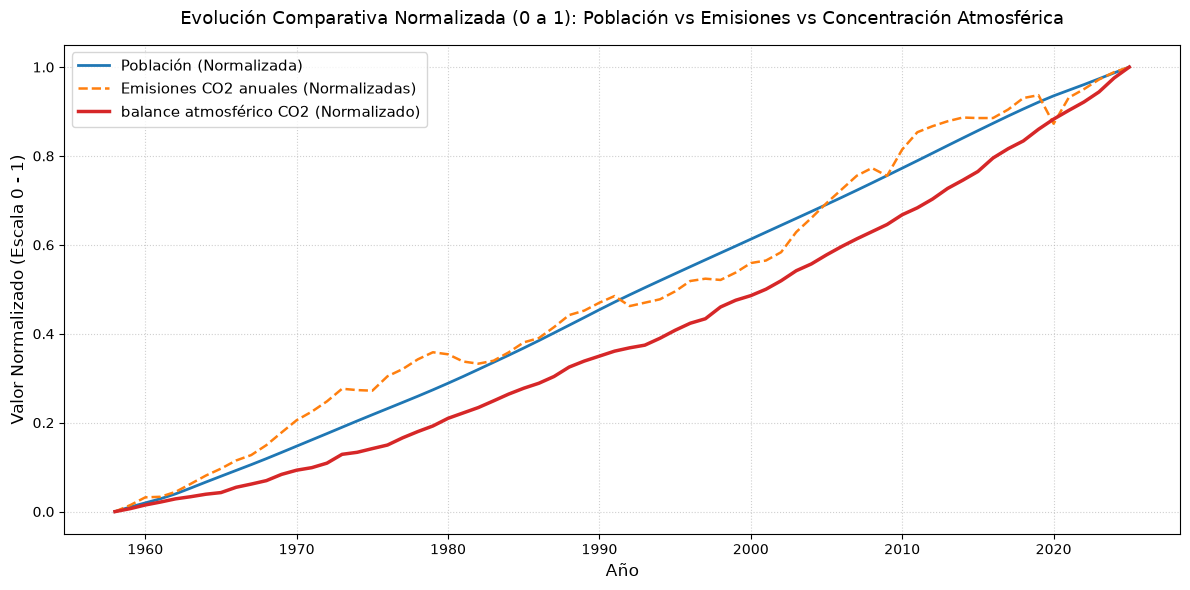

In [32]:
df_norm1 = df_final[["año"]].copy()
variables = ["población", "co2 (ppm)", "co2_promedio (ppm)"]

for var in variables:
    min_val = df_final[var].min()
    max_val = df_final[var].max()
    df_norm1[var + "_norm"] = (df_final[var] - min_val) / (max_val - min_val)

plt.figure(figsize=(12, 6)) #Tanteo hasta que queda bien
plt.plot(df_norm1["año"], df_norm1["población_norm"], color="tab:blue", linewidth=2, label="Población (Normalizada)")
plt.plot(df_norm1["año"], df_norm1["co2 (ppm)_norm"], color="tab:orange", linestyle="--", linewidth=1.8, label="Emisiones CO2 anuales (Normalizadas)")
plt.plot(df_norm1["año"], df_norm1["co2_promedio (ppm)_norm"], color="tab:red", linewidth=2.5, label="balance atmosférico CO2 (Normalizado)")

plt.title("Evolución Comparativa Normalizada (0 a 1): Población vs Emisiones vs Concentración Atmosférica", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=12)
plt.ylabel("Valor Normalizado (Escala 0 - 1)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=11)

plt.tight_layout()
plt.show()



Comentarios a la gráfica anterior: no me aporta información que represente la realidad. La descarto

Y sin normalizar pero con varias escalas en el eje Y

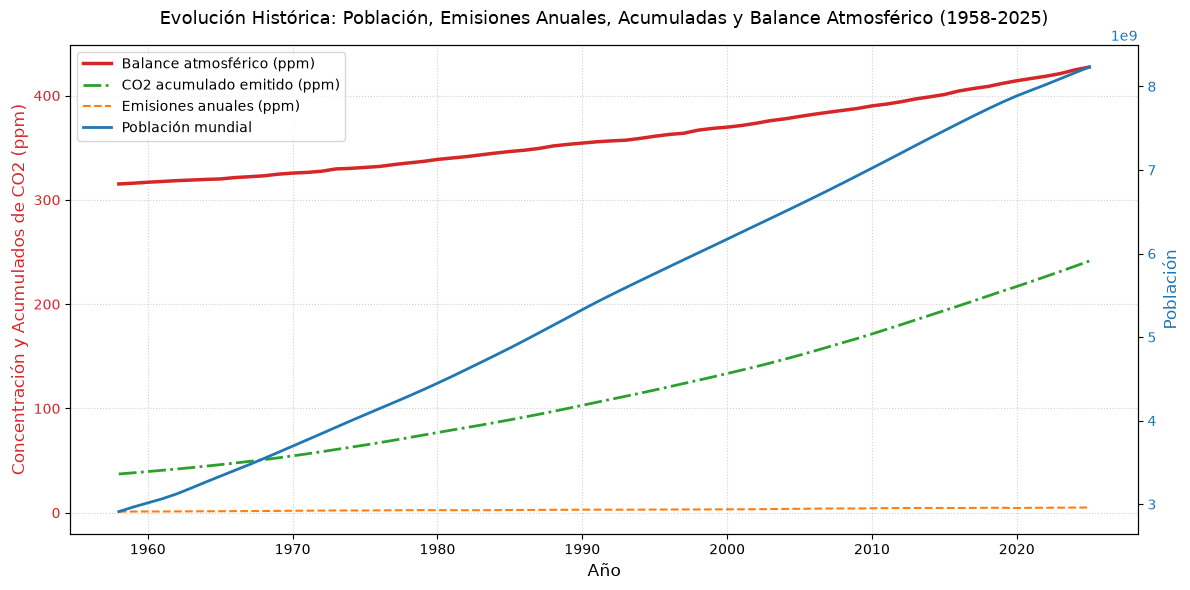

In [33]:

fig, ax1 = plt.subplots(figsize=(12, 6)) # Es el estándar para que me ocupe la pantalla


ax1.plot(df_final["año"], df_final["co2_promedio (ppm)"], color="tab:red", linewidth=2.5, label="Balance atmosférico (ppm)")
ax1.plot(df_final["año"], df_final["co2_acumulado (ppm)"], color="tab:green", linestyle="-.", linewidth=2, label="CO2 acumulado emitido (ppm)")
ax1.plot(df_final["año"], df_final["co2 (ppm)"], color="tab:orange", linestyle="--", linewidth=1.5, label="Emisiones anuales (ppm)")

ax1.set_xlabel("Año", fontsize=12)
ax1.set_ylabel("Concentración y Acumulados de CO2 (ppm)", color="tab:red", fontsize=12)
ax1.tick_params(axis="y", labelcolor="tab:red")
ax1.grid(True, linestyle=":", alpha=0.6)


ax2 = ax1.twinx()
ax2.plot(df_final["año"], df_final["población"], color="tab:blue", linewidth=2, label="Población mundial")

ax2.set_ylabel("Población", color="tab:blue", fontsize=12)
ax2.tick_params(axis="y", labelcolor="tab:blue")


plt.title("Evolución Histórica: Población, Emisiones Anuales, Acumuladas y Balance Atmosférico (1958-2025)", fontsize=13, pad=15)


lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

Comentarios de la gráfica anterior:
- Crecimiento Demográfico Sostenido (Población mundial): la curva azul muestra una progresión constante y muy vertical, multiplicando por más de 2,7 la población del planeta desde los ~3.000 millones de habitantes en 1958 hasta superar los 8.000 millones en la actualidad.
- Aceleración del Balance Atmosférico (Curva Roja): el registro directo de la NOAA refleja un incremento ininterrumpido de la concentración de CO2, escalando desde las 315.24 ppm iniciales hasta rebasar los umbrales de 427 ppm, sin indicios de estabilización ni cambio de tendencia.
- Inercia Estructural del Sistema: la trayectoria de la curva roja demuestra una absoluta inercia histórica; a pesar de la creciente conciencia ambiental y los marcos de transición energética, el volumen de gases de efecto invernadero sigue acumulándose de forma implacable año tras año.

Pero queremos ver cómo varía el balance atmosférico respecto a la emisión de co2 antropogénico. 

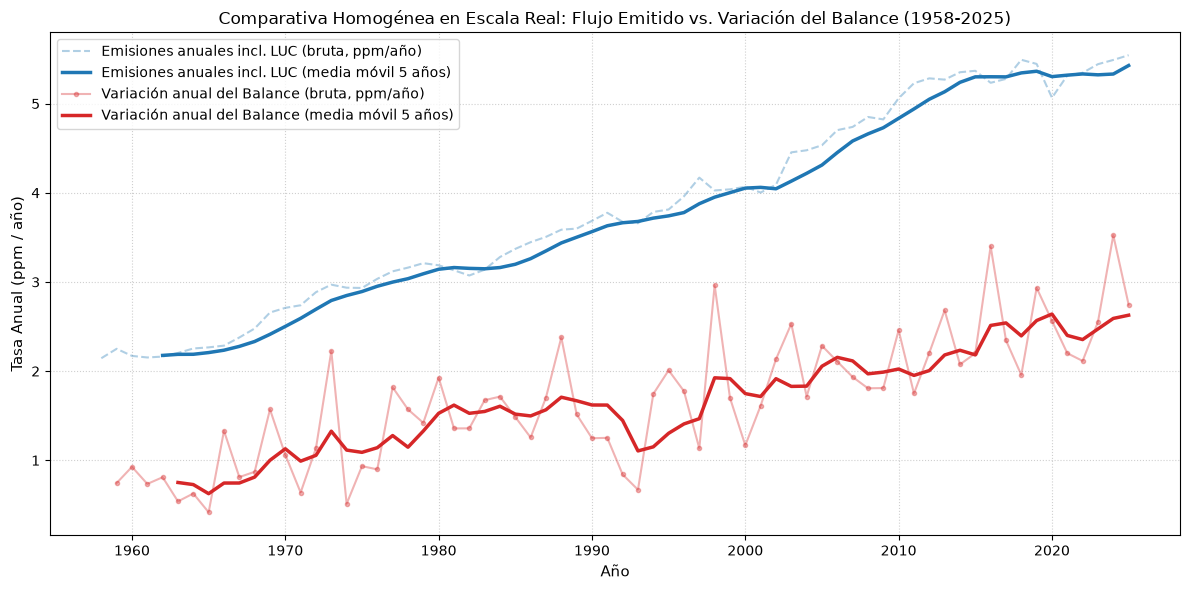

In [34]:
# 1. Calculo el incremento anual real del Balance (ppm/año)
df_final["variacion_balance_anual"] = df_final["co2_promedio (ppm)"].diff()

# 2. Me salen demasiados picos, así que suavizo ambas tasas con media móvil de 5 años para comparar ciclos reales
df_final["variacion_balance_5a"] = df_final["variacion_balance_anual"].rolling(window=5).mean()
df_final["emisiones_luc_5a"] = df_final["co2_incluyendo_luc (ppm)"].rolling(window=5).mean()

# 3. Gráfico de eje único y escala real (ppm/año)
plt.figure(figsize=(12, 6))

plt.plot(df_final["año"], df_final["co2_incluyendo_luc (ppm)"], color="tab:blue", alpha=0.35, linestyle="--", label="Emisiones anuales incl. LUC (bruta, ppm/año)")

plt.plot(df_final["año"], df_final["emisiones_luc_5a"], color="tab:blue", linewidth=2.5, label="Emisiones anuales incl. LUC (media móvil 5 años)")

plt.plot(df_final["año"], df_final["variacion_balance_anual"], color="tab:red", alpha=0.35, marker="o", markersize=3, label="Variación anual del Balance (bruta, ppm/año)")

plt.plot(df_final["año"], df_final["variacion_balance_5a"], color="tab:red", linewidth=2.5, label="Variación anual del Balance (media móvil 5 años)")

plt.title("Comparativa Homogénea en Escala Real: Flujo Emitido vs. Variación del Balance (1958-2025)", fontsize=12)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Tasa Anual (ppm / año)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

Comentarios al gráfico anterior:
- Trayectoria del Flujo Emitido (Curvas Azules): la línea sólida (media móvil de 5 años) muestra una pendiente ascendente muy constante y suave, pasando de unos 2,2 ppm/año a principios de los 60 hasta situarse alrededor de 5,4 ppm/año en 2025. La curva bruta discontinua apenas se desvía de su media móvil, salvo pequeños baches puntuales como el frenazo de 2020 (~5,1 ppm/año).
- Dinámica de la Variación del Balance (Curvas Rojas): A diferencia de la suavidad del flujo emitido, la serie bruta (puntos rosados) presenta una oscilación cíclica muy marcada de entre 3 y 7 años, con picos pronunciados (como los cercanos a 3,0 ppm/año en 1998, 3,4 en 2016 o 3,5 en 2024) y caídas bruscas por debajo de 1,0 ppm/año en varias décadas. Su media móvil de 5 años (línea roja gruesa) sube desde ~0,7 ppm/año en los años 60 hasta situarse en torno a 2,6 ppm/año en el tramo final.
- La relación entre ambas curvas no es ni siquiera constante ni lineal tramo a tramo: la brecha entre ambas curvas se ensancha en unas décadas (como en los 90, donde el flujo sube y el crecimiento del Balance cae) y se estrecha en otras (como entre 2010 y 2020, donde el flujo azul se aplana alrededor de 5,3 ppm/año y el Balance rojo sigue subiendo de ~2,0 a ~2,6 ppm/año).


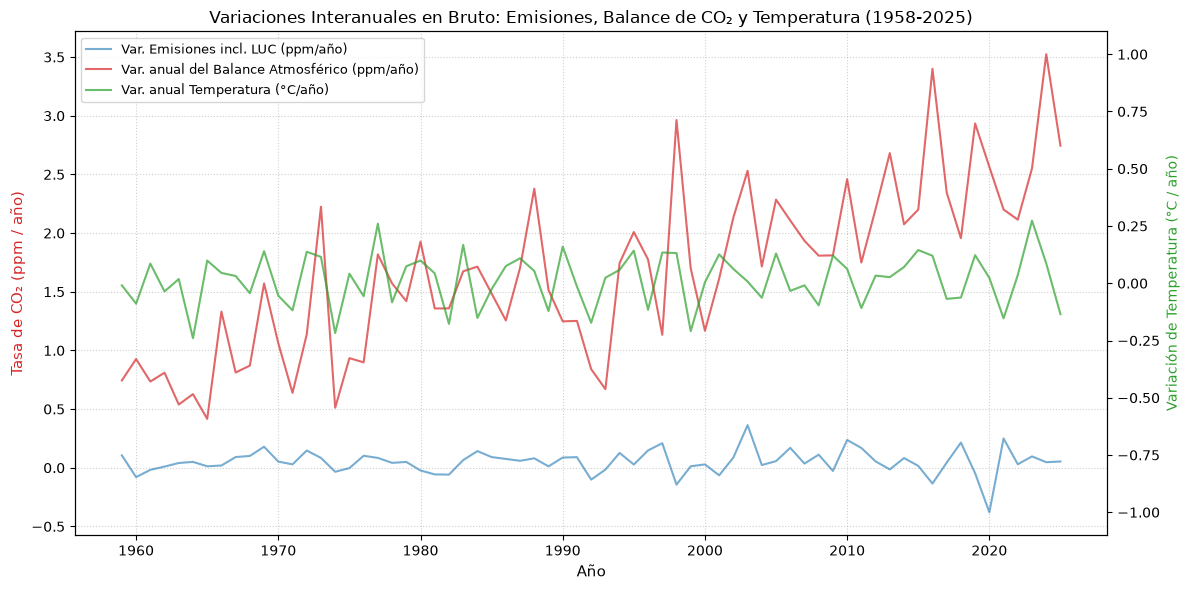

In [47]:
# 1. Calcul0 los incrementos anuales en bruto de las tres variables
df_final["variacion_emisiones_anual"] = df_final["co2_incluyendo_luc (ppm)"].diff()
df_final["variacion_balance_anual"] = df_final["co2_promedio (ppm)"].diff()
df_final["variacion_temperatura_anual"] = df_final["temp_media(Cº)"].diff()

fig, ax1 = plt.subplots(figsize=(12, 6))

# --- EJE y IZQUIERDO: Variación de Emisiones y Balance de CO₂ (ppm/año) ---
ax1.plot(df_final["año"], df_final["variacion_emisiones_anual"], color="tab:blue", alpha=0.6, linestyle="-", linewidth=1.5, label="Var. Emisiones incl. LUC (ppm/año)")
ax1.plot(df_final["año"], df_final["variacion_balance_anual"], color="tab:red", alpha=0.7, linestyle="-", linewidth=1.5, label="Var. anual del Balance Atmosférico (ppm/año)")
ax1.set_xlabel("Año", fontsize = 11)
ax1.set_ylabel("Tasa de CO₂ (ppm / año)", fontsize = 11, color = "tab:red")
ax1.grid(True, linestyle = ":", alpha = 0.6)

# --- EJE y DERECHO: Variación Anual de Temperatura (°C/año) ---
ax2 = ax1.twinx()
ax2.plot(df_final["año"], df_final["variacion_temperatura_anual"], color="tab:green", alpha=0.7, linestyle="-", linewidth=1.5, label="Var. anual Temperatura (°C/año)")
ax2.set_ylim(-1.1, 1.1)
ax2.set_ylabel("Variación de Temperatura (°C / año)", fontsize = 10, color = "tab:green")
ax2.grid(False)  # Quedaba feo y así se evita que se solapen las líneas de la cuadrícula


lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc = "upper left", fontsize = 9)

plt.title("Variaciones Interanuales en Bruto: Emisiones, Balance de CO₂ y Temperatura (1958-2025)", fontsize = 12)
plt.tight_layout()
plt.show()

# Comentarios al gráfico anterior
1. Desacoplamiento entre emisiones y acumulación a corto plazo:
El hecho de que la curva roja (balance) fluctúe de manera tan violenta mientras la curva azul (emisiones) permanece estable demuestra que las emisiones humanas anuales no dictan los altibajos interanuales de la acumulación atmosférica. Hay otro factor externo que modula fuertemente cuánto CO₂ absorbe o libera el planeta cada año.

2. La fuerte sincronía entre la temperatura y los sumideros naturales:
Si observamos la interacción entre la variación térmica (verde) y la variación del balance (roja), se aprecia un acoplamiento claro: los años de aceleración térmica acusada (picos verdes pronunciados) coinciden de forma muy directa con saltos masivos en la acumulación de CO₂ en la atmósfera (picos rojos).

3. Saturación de los sumideros por estrés térmico:
Este comportamiento confirma que la respuesta térmica del planeta interrumpe y debilita la capacidad de absorción de los sumideros naturales (océanos y bosques). Cuando la temperatura global experimenta saltos positivos bruscos, los sumideros terrestres sufren estrés (sequías, incendios, menor solubilidad oceánica), liberando o dejando de absorber grandes volúmenes de carbono, lo que explica que el balance atmosférico se dispare de manera independiente a lo que hayamos emitido ese año preciso en la industria.

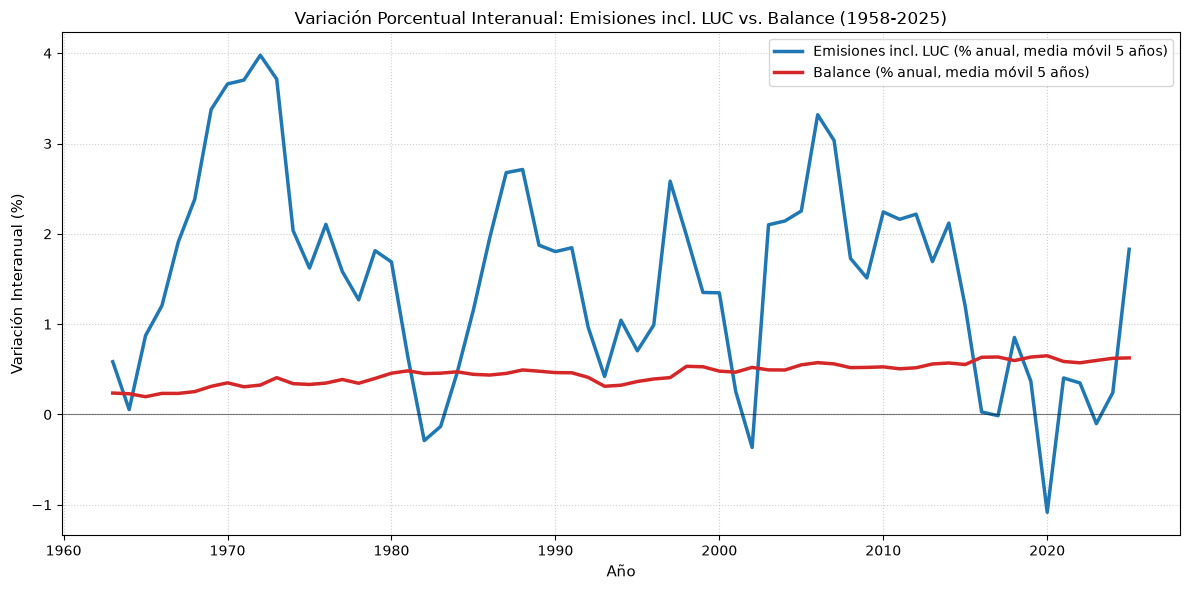

In [32]:
# 1. Calculo la variación porcentual interanual (%) de ambas series
df_final["var_pct_balance"] = df_final["co2_promedio (ppm)"].pct_change() * 100
df_final["var_pct_luc"] = df_final["co2_incluyendo_luc (ppm)"].pct_change() * 100

# 2. Suavizo con media móvil de 5 años
df_final["var_pct_balance_5a"] = df_final["var_pct_balance"].rolling(window=5).mean()
df_final["var_pct_luc_5a"] = df_final["var_pct_luc"].rolling(window=5).mean()

plt.figure(figsize=(12, 6))

plt.plot(df_final["año"], df_final["var_pct_luc_5a"], color="tab:blue", linewidth=2.5, label="Emisiones incl. LUC (% anual, media móvil 5 años)")

plt.plot(df_final["año"], df_final["var_pct_balance_5a"], color="tab:red", linewidth=2.5, label="Balance (% anual, media móvil 5 años)")

plt.axhline(y=0, color="black", linewidth=0.8, alpha=0.5)
plt.title("Variación Porcentual Interanual: Emisiones incl. LUC vs. Balance (1958-2025)", fontsize=12)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Variación Interanual (%)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

### Comentarios al gráfico anterior
A lo largo de la ventana 1958-2025, la tasa de crecimiento relativo de las emisiones tiende a moderarse (bajando de picos del 4% a oscilaciones entre 0% y 2% en los últimos años), mientras que la tasa de crecimiento relativo del Balance sigue ganando ritmo poco a poco. Esto confirma visualmente que el comportamiento de la atmósfera responde a una dinámica de acumulación de largo recorrido y a la regulación de los sumideros naturales, más que a las fluctuaciones anuales del flujo de emisiones.


# La fracción aerotransportada 
La fracción aerotransportada es el porcentaje del dióxido de carbono (CO2) emitido por la actividad humana (combustibles fósiles, industria y cambios de uso del suelo) que permanece en la atmósfera en lugar de ser absorbido y retenido por los sumideros naturales de la Tierra (los océanos y la biosfera terrestre, como los bosques y la vegetación).

Se calcula matemáticamente de forma muy directa para un año determinado:

    Fracción Aerotransportada = Aumento anual de CO2 en la atmósfera / Emisiones antropogénicas totales emitidas ese año

Es uno de los ratios más importantes que los observadores analizan porque han determinado que mientras la Fracción Aerotransportada esté estable por debajo del 50%, el planeta tiene capacidad para absorber el 50% del co2 antropogénico que emitimos. ¿Por qué? Así se ha estado registrando desde 1958. Si en un momento dado esa línea se rebasara, se consideraría que hemos saturado la capacidad de los sumideros naturales. No se ha llegado nunca a este punto. De hecho actualmente el valor es del 43,60 %.

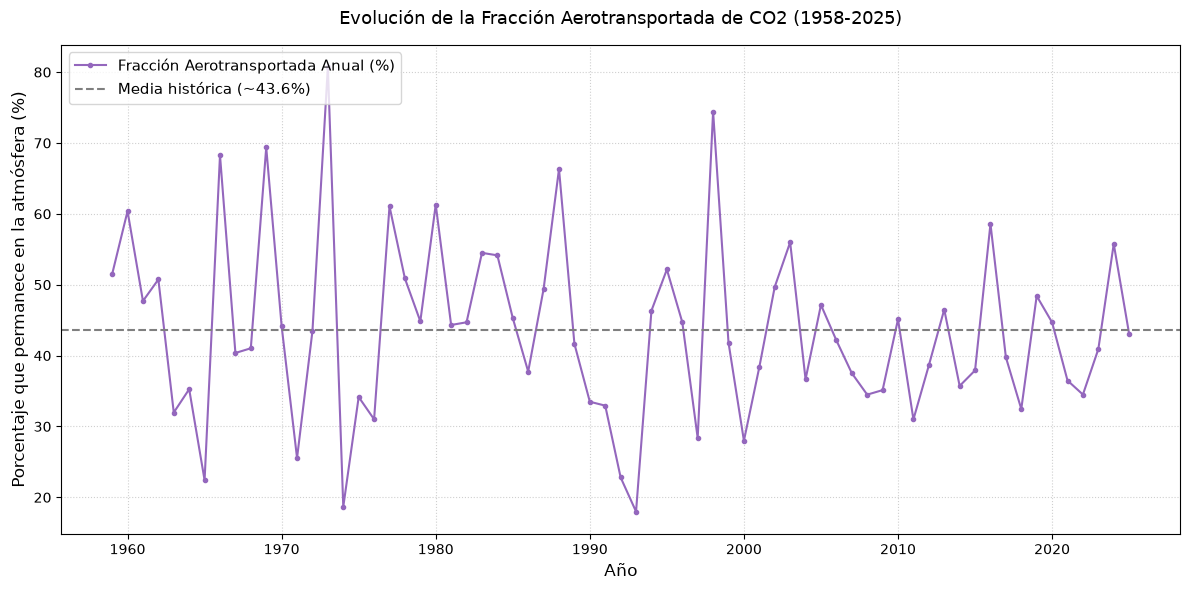

In [ ]:
# 1. Calculo el incremento anual de CO2 en la atmósfera
df_final["incremento_atmosferico_ppm"] = df_final["co2_promedio (ppm)"].diff()

# 2. Calculo la fracción aerotransportada relacionando el incremento con las emisiones totales
df_final["fraccion_aerotransportada_pct"] = (df_final["incremento_atmosferico_ppm"] / df_final["co2 (ppm)"]) * 10

plt.figure(figsize=(12, 6))

plt.plot(df_final["año"][1:], df_final["fraccion_aerotransportada_pct"][1:], color="tab:purple", marker="o", markersize=3, linestyle="-", linewidth=1.5, label="Fracción Aerotransportada Anual (%)")

# Línea de media histórica
media_historica = df_final["fraccion_aerotransportada_pct"].mean()
plt.axhline(y=media_historica, color="tab:gray", linestyle="--", label=f"Media histórica (~{media_historica:.1f}%)")

plt.title("Evolución de la Fracción Aerotransportada de CO2 (1958-2025)", fontsize = 13, pad = 15)
plt.xlabel("Año", fontsize = 12)
plt.ylabel("Porcentaje que permanece en la atmósfera (%)", fontsize = 12)
plt.grid(True, linestyle = ":", alpha = 0.6)
plt.legend(loc = "upper left", fontsize = 11)

plt.tight_layout()
plt.show()

### Comentarios al gráfico anterior
1. Confirmación numérica de la baja correlación interanual: este gráfico demuestra que la variación anual del Balance no copia el ritmo de las emisiones anuales. Si hubiera una relación rígida o proporcional año a año, la línea morada sería casi horizontal. En cambio, oscila entre el 18% y el 81% porque la respuesta neta de la atmósfera cada año depende fuertemente de la variabilidad interna de los sumideros naturales (ciclos oceánicos, temperatura y dinámica de la biosfera).   
2. Estabilidad del reparto a largo plazo (sin signos de saturación): pese a que el flujo de emisiones anuales se ha más que duplicado desde 1958, la proporción media que permanece en el aire se mantiene estable en torno al ~43,6% (e incluso muestra menor amplitud de picos extremos en los últimos 20 años que en los primeros 20). Los datos no muestran que el porcentaje de retención atmosférica esté aumentando a lo largo del periodo observado.  

# Curisidad
Vamos a ver la gráfica de emisiones de co2 asociadas a la actividad humana de agricultura y deforestación

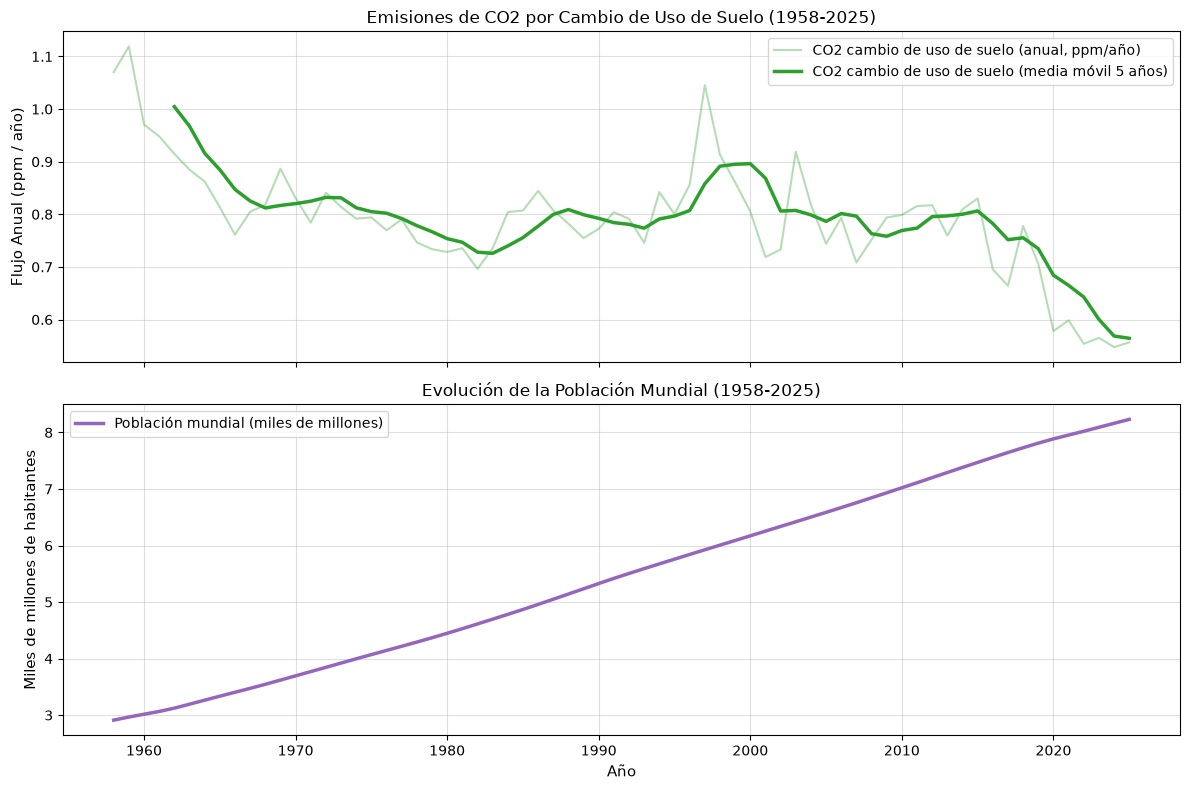

In [36]:
# 1. Gráficas independientes en sus unidades reales (sin doble eje Y)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Subgráfico 1: Emisiones por cambio de uso de suelo (ppm/año)
df_final["co2_luc_5a"] = df_final["co2_cambio_uso_suelo (ppm)"].rolling(window=5).mean()

ax1.plot(df_final["año"], df_final["co2_cambio_uso_suelo (ppm)"], color="tab:green", alpha=0.35, linewidth=1.5, label="CO2 cambio de uso de suelo (anual, ppm/año)")
ax1.plot(df_final["año"], df_final["co2_luc_5a"], color="tab:green", linewidth=2.5, label="CO2 cambio de uso de suelo (media móvil 5 años)")
ax1.set_title("Emisiones de CO2 por Cambio de Uso de Suelo (1958-2025)", fontsize=12)
ax1.set_ylabel("Flujo Anual (ppm / año)", fontsize=11)
ax1.grid(True, alpha=0.4)
ax1.legend(loc="upper right", fontsize=10)

# Subgráfico 2: Población mundial
ax2.plot(df_final["año"], df_final["población"] / 1e9, color="tab:purple", linewidth=2.5, label="Población mundial (miles de millones)")
ax2.set_title("Evolución de la Población Mundial (1958-2025)", fontsize=12)
ax2.set_xlabel("Año", fontsize=11)
ax2.set_ylabel("Miles de millones de habitantes", fontsize=11)
ax2.grid(True, alpha=0.4)
ax2.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

### Comentarios sobre los gráficos anteriores
Las dos gráficas presentan una comparativa visual fundamental para evaluar cómo se comportan dos variables socioambientales clave dentro del registro instrumental (1958-2025): el flujo de emisiones por cambio de uso de suelo (deforestación y transformación agrícola) frente al crecimiento demográfico mundial.
- Desacople absoluto (Ausencia de correlación demográfica): no existe ninguna relación proporcional ni paralelismo entre ambas curvas. Mientras la población mundial se ha multiplicado por más de 2,5, el volumen absoluto de emisiones de CO2 procedentes del cambio de uso de suelo no ha crecido, sino que muestra una leve tendencia a la baja.
- Esto demuestra empíricamente que el crecimiento demográfico global no arrastra un incremento lineal de la deforestación neta, evidenciando que la transformación de la superficie forestal responde a dinámicas socioeconómicas, agrícolas, comerciales y de eficiencia tecnológica muy localizadas y ajenas a una correlación demográfica directa a escala global.


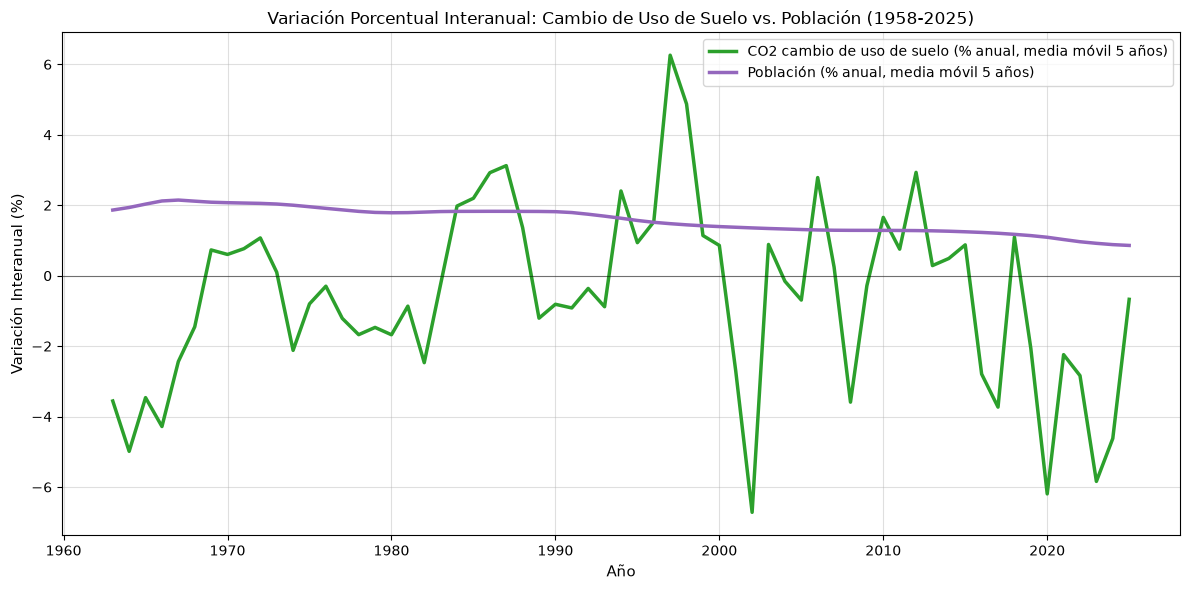

In [35]:
# 1. Comparativa directa en eje único adimensional (% anual, media móvil 5 años)
df_final["var_pct_luc_5a"] = (df_final["co2_cambio_uso_suelo (ppm)"].pct_change() * 100).rolling(window=5).mean()
df_final["var_pct_pob_5a"] = (df_final["población"].pct_change() * 100).rolling(window=5).mean()

plt.figure(figsize=(12, 6))

plt.plot(df_final["año"], df_final["var_pct_luc_5a"], color="tab:green", linewidth=2.5, label="CO2 cambio de uso de suelo (% anual, media móvil 5 años)")

plt.plot(df_final["año"], df_final["var_pct_pob_5a"], color="tab:purple", linewidth=2.5, label="Población (% anual, media móvil 5 años)")

plt.axhline(y=0, color="black", linewidth=0.8, alpha=0.5)
plt.title("Variación Porcentual Interanual: Cambio de Uso de Suelo vs. Población (1958-2025)", fontsize=12)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Variación Interanual (%)", fontsize=11)
plt.grid(True, alpha=0.4)
plt.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

### Comentarios al gráfico anterior
1. Crecimiento de la Población (% anual, curva púrpura):
- Dibuja una trayectoria extremadamente estable y de suave pendiente descendente.
- Parte de tasas de crecimiento cercanas al +2,1% anual a finales de los años 60 y se desacelera de forma paulatina hasta situarse en torno al +0,9% anual en el tramo final de la serie.   
2. Variación del Cambio de Uso de Suelo (% anual, curva verde):
- Muestra una altísima volatilidad y un comportamiento errático en forma de dientes de sierra.
- Cruza de manera constante la línea de equilibrio (0%), alternando periodos de aceleración de emisiones netas con años de descensos profundos.
- Presenta picos extremos muy marcados —como el pico superior al +6% a finales de los años 90— y valles acusados (como los registrados en torno a 2002 o 2020).   


### CONCLUSIONES FINALES
Hemos dado respuesta a las hipótesis planteadas:
1. El crecimiento demográfico global
Hipótesis a contrastar: correlacionar la expansión de la población mundial con el incremento absoluto de las emisiones agregadas.

- Resultado empírico y contrastación: DESMENTIDO.

- Si bien la población mundial ha experimentado un crecimiento masivo desde 1958 (pasando de 3.000 a 8.000 millones de habitantes), su tasa de crecimiento interanual se ha ido desacelerando progresivamente. Esta desaceleración demográfica "a la baja" no guarda una correlación directa ni proporcional con las emisiones agregadas de CO₂ ni con los picos de emisiones anuales, demostrando que el volumen de emisiones está impulsado por factores tecnológicos, energéticos e industriales mucho más que por el simple crecimiento lineal o volumétrico de la población.

2. Las emisiones antropogénicas directas
Hipótesis a contrastar: aislar y medir el peso específico de la quema de combustibles fósiles frente al balance global acumulado de carbono.

- Resultado empírico y contrastación: DESMENTIDO.

- Aunque la quema de combustibles fósiles genera un flujo bruto constante de emisiones antropogénicas, al aislar su peso específico frente al balance atmosférico global, los datos revelan que la fracción aerotransportada neta retenida se sitúa en torno al 43,6% (por debajo del umbral crítico del 50%). Al examinarlo bajo una perspectiva geológica y de ciclos macroclimáticos (escalas de 100.000 años frente a los poco más de 170 años de industrialización), las emisiones humanas representan una fracción temporal y cuantitativa menor que no dicta el ritmo de los grandes ciclos de concentración y temperatura de la Tierra.

3. La deforestación y el cambio de uso del suelo
Hipótesis a contrastar: cuantificar el impacto del deterioro de la superficie forestal en la reducción de las reservas de carbono en los ecosistemas.

- Resultado empírico y contrastación: MATIZADO (AISLADO A EVENTOS PUNTUALES).

- Las series temporales demuestran que las fluctuaciones en las emisiones derivadas del cambio de uso del suelo y la deforestación no responden a una tendencia demográfica ni a un declive sistemático y continuo de los sumideros terrestres. Por el contrario, las subidas y bajadas abruptas en este indicador responden de manera directa a acontecimientos puntuales y discretos (como grandes catástrofes de incendios forestales o planes específicos de conversión de suelo a escala regional), operando de forma independiente al volumen global de emisiones industriales.

4. La saturación o pérdida de eficiencia de los sumideros naturales
Hipótesis a contrastar: Evaluar si la capacidad de absorción de los océanos y los ecosistemas terrestres muestran signos de fatiga o estancamiento ante el volumen creciente de emisiones.

- Resultado empírico y contrastación: DESMENTIDO.

- Los datos empíricos del balance de carbono muestran que la capacidad de absorción del planeta no está colapsando ni se encuentra en una trayectoria de saturación proporcional a las emisiones. Por el contrario, los sumideros operan bajo dinámicas biogeoquímicas propias y desacopladas del ritmo de emisión industrial, absorbiendo de manera constante una proporción muy elevada del carbono total inyectado y manteniendo la fracción aerotransportada por debajo de los límites críticos de saturación sistémica.



